## Problema 3 — Classificação da Qualidade de Vinhos com KNN

### 1. Carregamento e Exploração dos Dados

In [1]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

# Carrega os dados
df = pd.read_csv(url, sep=";")

display(df.head())

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [2]:
print("Dimensões:", df.shape)

print("\nInformações gerais:")
df.info()

print("\nValores ausentes:")
print(df.isnull().sum())

print("\nEstatísticas descritivas:")
display(df.describe())

print("\nRegistros duplicados:", df.duplicated().sum())

Dimensões: (1599, 12)

Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB

Valores ausentes:
fixed acidity           0
volatile acidity        0
citric acid            

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000



Registros duplicados: 240


## 2. Preparação dos Dados

### 2.1. Recodificação da variável quality

In [3]:
# Defini as condições para cada classe
condicoes = [
    df["quality"] <= 5,
    df["quality"].between(6, 7),
    df["quality"] >= 8
]

classes = [0, 1, 2]

# Cria a nova variável alvo
df["classe"] = np.select(
    condicoes,
    classes,
    default=-1
)

print("Distribuição das classes:")
print(df["classe"].value_counts().sort_index())

print("\nVerificação de classes inválidas:")
print((df["classe"] == -1).sum())

Distribuição das classes:
classe
0    744
1    837
2     18
Name: count, dtype: int64

Verificação de classes inválidas:
0


In [4]:
distribuicao = df["classe"].value_counts().sort_index()

# Percentual de cada classe
percentuais = df["classe"].value_counts(
    normalize=True
).sort_index() * 100

# Organiza os resultados
tabela_classes = pd.DataFrame({
    "Quantidade": distribuicao,
    "Percentual (%)": percentuais
})

tabela_classes.index = ["Ruim", "Médio", "Bom"]

display(tabela_classes.round(2))

,Quantidade,Percentual (%)
Ruim,744,46.53
Médio,837,52.35
Bom,18,1.13


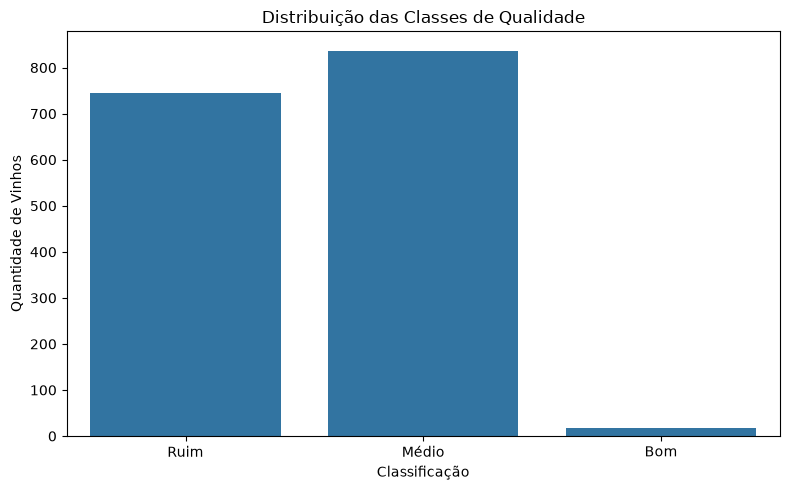

In [5]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="classe",
    order=[0, 1, 2]
)

plt.xticks(
    ticks=[0, 1, 2],
    labels=["Ruim", "Médio", "Bom"]
)

plt.xlabel("Classificação")
plt.ylabel("Quantidade de Vinhos")
plt.title("Distribuição das Classes de Qualidade")

plt.tight_layout()
plt.show()

### 2.2. Divisão dos dados em treino e teste

In [11]:
print("Amostras originais:", len(df))

# Remove registros completamente duplicados
df = df.drop_duplicates().reset_index(drop=True)

print("Amostras após tratamento:", len(df))

print("\nDistribuição das classes:")
print(df["classe"].value_counts().sort_index())

Amostras originais: 1599
Amostras após tratamento: 1359

Distribuição das classes:
classe
0    640
1    702
2     17
Name: count, dtype: int64


In [12]:
from sklearn.model_selection import train_test_split

# Separa as variáveis independentes
X = df.drop(columns=["quality", "classe"])

# Seleciona a variável alvo
y = df["classe"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Amostras de treino:", X_treino.shape)
print("Amostras de teste:", X_teste.shape)

print("\nDistribuição no treino:")
print(y_treino.value_counts().sort_index())

print("\nDistribuição no teste:")
print(y_teste.value_counts().sort_index())

print("\nRegistros duplicados:")
print(df.duplicated().sum())

Amostras de treino: (1087, 11)
Amostras de teste: (272, 11)

Distribuição no treino:
classe
0    512
1    561
2     14
Name: count, dtype: int64

Distribuição no teste:
classe
0    128
1    141
2      3
Name: count, dtype: int64

Registros duplicados:
0


### 2.3. Padronização dos atributos

In [13]:
from sklearn.preprocessing import StandardScaler

# Cria o padronizador
scaler = StandardScaler()

X_treino_pad = scaler.fit_transform(X_treino)

X_teste_pad = scaler.transform(X_teste)

print("Médias após padronização:")
print(X_treino_pad.mean(axis=0).round(4))

print("\nDesvios padrão:")
print(X_treino_pad.std(axis=0).round(4))

Médias após padronização:
[-0.  0.  0. -0. -0. -0. -0. -0.  0. -0. -0.]

Desvios padrão:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 2.4. Conversão dos dados para tensores PyTorch

In [14]:
# Converte as entradas para tensores
X_treino_tensor = torch.tensor(
    X_treino_pad,
    dtype=torch.float32
)

X_teste_tensor = torch.tensor(
    X_teste_pad,
    dtype=torch.float32
)

# Converte os rótulos para tensores
y_treino_tensor = torch.tensor(
    y_treino.to_numpy(),
    dtype=torch.long
)

y_teste_tensor = torch.tensor(
    y_teste.to_numpy(),
    dtype=torch.long
)

print("X treino:", X_treino_tensor.shape)
print("X teste:", X_teste_tensor.shape)

print("y treino:", y_treino_tensor.shape)
print("y teste:", y_teste_tensor.shape)

X treino: torch.Size([1087, 11])
X teste: torch.Size([272, 11])
y treino: torch.Size([1087])
y teste: torch.Size([272])


## 3. Implementação do Algoritmo KNN

### 3.1. Cálculo das distâncias e votação dos vizinhos

In [15]:
import torch.nn.functional as F

def prever_knn(X_base, y_base, X_consulta, k=5):

    # Calcula as distâncias euclidianas
    distancias = torch.cdist(
        X_consulta,
        X_base,
        p=2
    )

    # Seleciona os k vizinhos mais próximos
    indices = torch.topk(
        distancias,
        k=k,
        largest=False,
        dim=1
    ).indices

    # Recupera as classes dos vizinhos
    classes_vizinhos = y_base[indices]

    # Conta os votos de cada classe
    votos = F.one_hot(
        classes_vizinhos,
        num_classes=3
    ).sum(dim=1)

    # Seleciona a classe com mais votos
    previsoes = torch.argmax(votos, dim=1)

    return previsoes

### 3.2. Teste inicial do algoritmo

In [16]:
amostras = X_treino_tensor[:5]

previsoes = prever_knn(
    X_treino_tensor,
    y_treino_tensor,
    amostras,
    k=5
)

print("Classes reais:")
print(y_treino_tensor[:5].tolist())

print("\nClasses previstas:")
print(previsoes.tolist())

Classes reais:
[2, 1, 0, 1, 1]

Classes previstas:
[1, 1, 0, 1, 1]


In [17]:
# Seleciona a primeira amostra de treino
amostra = X_treino_tensor[0:1]

# Calcula distâncias
distancias = torch.cdist(
    amostra,
    X_treino_tensor,
    p=2
)

# Seleciona os cinco vizinhos mais próximos
valores, indices = torch.topk(
    distancias,
    k=5,
    largest=False
)

# Exibi resultados
for i in range(5):
    indice = indices[0, i].item()
    distancia = valores[0, i].item()
    classe = y_treino_tensor[indice].item()

    print(
        f"Vizinho {i+1}: "
        f"Distância = {distancia:.4f}, "
        f"Classe = {classe}"
    )

Vizinho 1: Distância = 0.0000, Classe = 2
Vizinho 2: Distância = 0.9695, Classe = 1
Vizinho 3: Distância = 1.0132, Classe = 1
Vizinho 4: Distância = 1.1313, Classe = 1
Vizinho 5: Distância = 1.2037, Classe = 1
